# 3. The same tests on another ensemble

Notebooks 1 and 2 step through the analysis for CMIP6. This notebook runs the same steps on any ensemble
(for example WIEMIP) using the packaged versions in `tcre_evidence.process_tests` and
`tcre_evidence.process_plots`. It is set up for the CMIP6 example so that it runs as it stands.

Inputs (details in `docs/new_ensemble.md`):

* a values CSV with a `model` column and one column per quantity (name the β/γ convention, e.g.
  `gamma_land_coubgc`);
* a flags CSV with a `model` column, one 0/1 column per process (e.g. `demography`) and, optionally, a
  `family` column.

In [1]:
import numpy as np
import pandas as pd

from tcre_evidence import process_plots as pp, process_tests as pt
from tcre_evidence.paths import DATA

pd.set_option("display.precision", 2)

NAME = "cmip6"                    # name of this ensemble's cache, e.g. "wiemip"
VALUES = DATA / "examples" / "cmip6_land_feedbacks.csv"
FLAGS = DATA / "examples" / "cmip6_process_flags.csv"
QUANTITY = "gamma_land_coubgc"    # a column of VALUES
KIND = "additive"                 # "additive" for gamma (PgC/K), "multiplicative" for beta (PgC/ppm)
LABEL = "γ_L (PgC/K)"

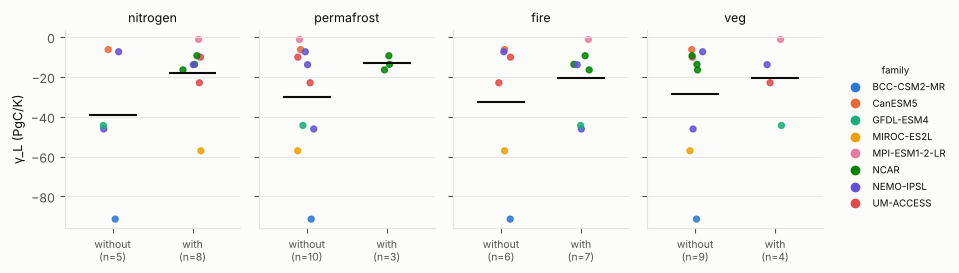

In [2]:
y, flags, family = pt.load_ensemble(VALUES, FLAGS, QUANTITY)
pp.by_flag(y, flags, family, LABEL);

flags explain 20% of the spread; each model predicted from the others: -0.70


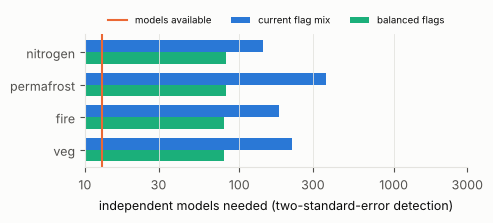

In [3]:
yy = np.log(y) if KIND == "multiplicative" else y
b = pt.flag_budget(yy, flags)
print(f"flags explain {b['r2']:.0%} of the spread; each model predicted from the others: {b['loo_q2']:.2f}")
pp.power(pt.detection_power(yy, flags, {p: 0.5 * yy.std() for p in flags.columns}));

The Bayesian tests need sampling. Run the command printed below in a terminal (a few minutes with
`--quick`, about an hour without), then run the remaining cells.

In [4]:
print(f"python scripts/precompute.py --name {NAME} --values {VALUES} --flags {FLAGS} "
      f"--quantities {QUANTITY}:{KIND} --jobs 4")

python scripts/precompute.py --name cmip6 --values /home/user/tcre_mini/data/examples/cmip6_land_feedbacks.csv --flags /home/user/tcre_mini/data/examples/cmip6_process_flags.csv --quantities gamma_land_coubgc:additive --jobs 4


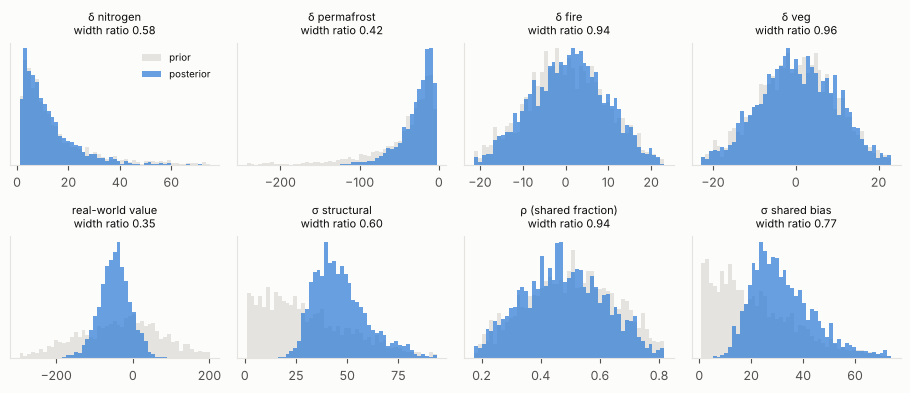

In [5]:
res = pp.load(NAME, QUANTITY)
pp.prior_posterior(res);

,process,models_available,models_needed,tracking,sd_over_effect,width_ratio
0,nitrogen,13,143,0.21,0.68,0.58
1,permafrost,13,364,-0.02,1.83,0.42
2,fire,13,182,0.14,0.72,0.94
3,veg,13,221,0.15,0.73,0.96


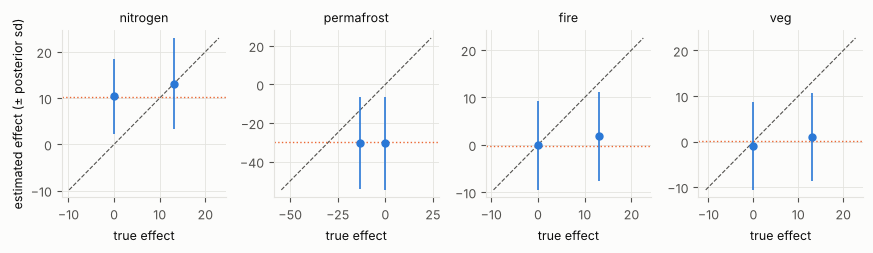

In [6]:
pp.recovery(res);
pt.evidence_table(res["prior_vs_posterior"], res["synthetic_effects_summary"],
                  res["synthetic_no_effects_summary"], res["power"])

,method,crps,bias,cov66,cov90,mean_sd,crps_skill
0,all_processes_on,22.47,-26.52,0.46,1.00,47.56,-0.41
1,own_flags,25.28,-14.40,0.69,0.92,67.43,-0.58
2,raw_ensemble,15.98,-1.50,0.85,0.92,32.20,0.00


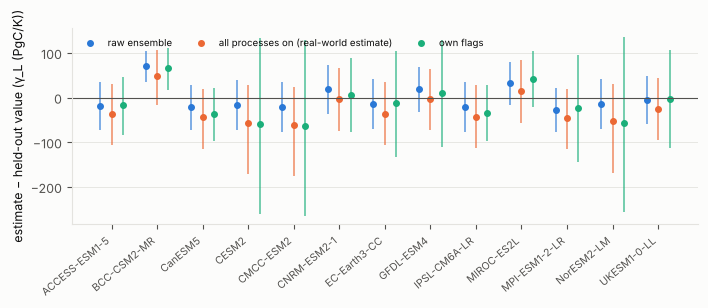

In [7]:
pp.loo(res, LABEL);
res["loo_summary"]

Before quoting a number: `rhat_max` below 1.01 and few or no divergences, no `--quick` runs.
`res["run"]` records the priors, effect sizes, settings and package versions used.

In [8]:
res["run"]["diagnostics"]

{'prior_vs_posterior': {'rhat_max': 1.0016474913472393,
  'ess_bulk_min': 2721.2484540275073,
  'ess_tail_min': 2151.996586712873,
  'divergences': 0,
  'n_draws': 4000},
 'synthetic_effects': {'rhat_max': 1.0027343317062776, 'divergences': 0},
 'synthetic_no_effects': {'rhat_max': 1.0043849308670865, 'divergences': 0},
 'loo': {'rhat_max': 1.0030749253579043,
  'divergences': 0,
  'held_out': 'family'}}